# 01 — Problem Framing: Incrementality, Not Conversion

**Question.** Out of a fixed marketing budget, who should we contact so the spend actually *causes* extra conversions, rather than rewarding people who would have converted anyway?

This notebook frames the project. It introduces the difference between response modelling and uplift modelling, lays out the decision the rest of the project supports, and shows on the active dataset that ranking by predicted *conversion probability* targets a different population than ranking by *causal uplift*. Subsequent notebooks build the data view, models, evaluation, and policy.

## 1. The decision being supported

A campaign team has a finite contact budget. For each customer they must decide:

- treat now,
- hold out,
- defer to a cheaper channel.

The economically relevant quantity is **incremental conversions**, not total conversions, because conversions that would have happened anyway do not justify the marginal contact cost.

## 2. Response modelling vs uplift modelling

| Modelling target | Quantity estimated | Ranks well for |
|---|---|---|
| Response | $P(Y = 1 \mid X)$ | scoring likely converters |
| Uplift   | $P(Y = 1 \mid X, T = 1) - P(Y = 1 \mid X, T = 0)$ | scoring customers the campaign actually moves |

Response models inflate spend on **sure things** — customers with high baseline conversion who do not need the contact. Uplift models try to identify **persuadables** — customers whose conversion probability rises *because of* the contact.

## 3. The four-segment lens

The standard partition used throughout the project:

- **Persuadable** — converts iff treated. *Target.*
- **Sure thing** — converts under either arm. *Save the spend.*
- **Lost cause** — never converts. *Save the spend.*
- **Do-not-disturb** — treatment lowers conversion. *Avoid.*


In [1]:
import sys
from pathlib import Path

_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(_ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from uplift_marketing.notebook_utils import setup_notebook, save_figure
from uplift_marketing.data import load_default_uplift_data

config = setup_notebook()
RANDOM_STATE = 42

dataset = load_default_uplift_data(config.raw_dir, random_state=RANDOM_STATE)
data = dataset.data
print(f"data source: {dataset.source} ({len(data):,} rows)")
print(f"observed treated share: {data['treatment'].mean():.3f} "
      f"(expected {dataset.expected_treated_share:.3f})")
print(f"feature columns to exclude: {dataset.extra_excluded}")


data source: hillstrom (64,000 rows)
observed treated share: 0.667 (expected 0.667)
feature columns to exclude: ['customer_id']


## 4. The data in one line

All notebooks share a single loader,
[`load_default_uplift_data`](../src/uplift_marketing/data.py),
which prefers the real Hillstrom MineThatData email-marketing dataset when its CSV is present under `data/raw/`, and falls back to the synthetic generator otherwise. Both datasets expose the same `treatment` / `conversion` schema, so the analyses below are agnostic to the source.

In [2]:
from uplift_marketing.treatment import naive_average_treatment_effect, outcome_by_treatment

ate = naive_average_treatment_effect(data)
by_arm = outcome_by_treatment(data)
print(f"naive ATE (treated - control conversion rate): {ate:+.4f}")
by_arm

naive ATE (treated - control conversion rate): +0.0050


,treatment,n,outcome_rate,positives
0,0,21306,0.005726,122
1,1,42694,0.010681,456


## 5. Demonstration: ranking by conversion likelihood is not ranking by uplift

Fit a quick response model on the *control* arm only (so its score is unaware of the treatment effect), use it to rank everyone by predicted conversion probability, and read off how the **observed** treated-control gap evolves across response deciles. If response-ranking were a good uplift policy, the observed lift would be highest in the top decile.

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from uplift_marketing.features import (
    infer_feature_spec,
    build_preprocessor,
    split_features_treatment_outcome,
)

spec = infer_feature_spec(data, extra_excluded=dataset.extra_excluded)
x, treatment, y = split_features_treatment_outcome(data, spec)

control_mask = treatment.eq(0)
response_model = Pipeline(
    [
        ("preprocessor", build_preprocessor(spec)),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]
).fit(x[control_mask], y[control_mask])

scored = data.copy()
scored["response_score"] = response_model.predict_proba(x)[:, 1]
scored["response_decile"] = (
    pd.qcut(scored["response_score"].rank(method="first", ascending=False), 10, labels=False) + 1
)
decile_summary = (
    scored.groupby("response_decile")
    .apply(
        lambda g: pd.Series(
            {
                "n": len(g),
                "treated_rate": g.loc[g.treatment == 1, "conversion"].mean(),
                "control_rate": g.loc[g.treatment == 0, "conversion"].mean(),
                "observed_uplift": (
                    g.loc[g.treatment == 1, "conversion"].mean()
                    - g.loc[g.treatment == 0, "conversion"].mean()
                ),
            }
        ),
        include_groups=False,
    )
    .reset_index()
)
decile_summary

,response_decile,n,treated_rate,control_rate,observed_uplift
0,1,6400.0,0.018952,0.013170,0.005782
1,2,6400.0,0.015552,0.011472,0.004080
2,3,6400.0,0.012476,0.009294,0.003183
3,4,6400.0,0.011806,0.005288,0.006517
4,5,6400.0,0.009379,0.004215,0.005163
5,6,6400.0,0.007069,0.004174,0.002894
6,7,6400.0,0.011072,0.001856,0.009216
7,8,6400.0,0.005898,0.005553,0.000345
8,9,6400.0,0.008511,0.002304,0.006206
9,10,6400.0,0.006017,0.000000,0.006017


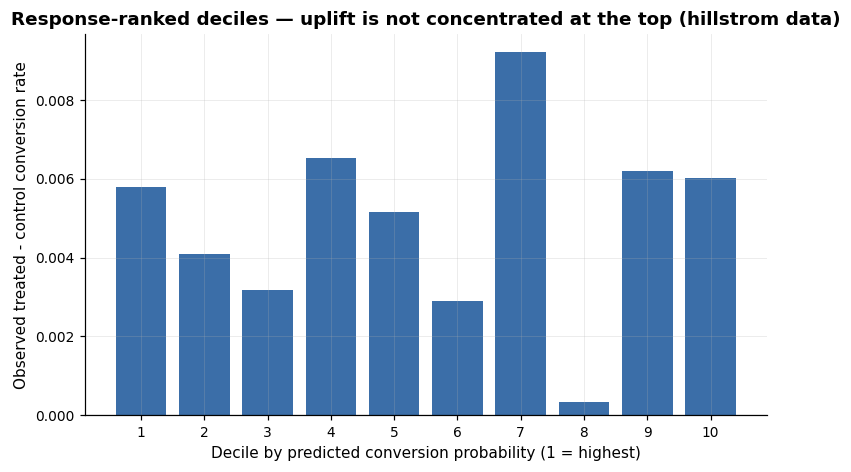

In [4]:
fig, ax = plt.subplots()
ax.bar(decile_summary["response_decile"], decile_summary["observed_uplift"], color="#3b6ea8")
ax.axhline(0, color="black", linewidth=0.7)
ax.set_xlabel("Decile by predicted conversion probability (1 = highest)")
ax.set_ylabel("Observed treated - control conversion rate")
ax.set_title(
    f"Response-ranked deciles — uplift is not concentrated at the top "
    f"({dataset.source} data)"
)
ax.set_xticks(decile_summary["response_decile"])
save_figure(fig, "01_response_decile_uplift")
plt.show()

**Reading the chart.** If the response score were a good uplift ranker, the leftmost (top) deciles would show the largest observed treated-control gap. The pattern across response deciles is flat or inverted: the highest baseline-converters are largely sure-things. The next notebooks build estimators that target the right quantity directly.

## 6. Notebook map

| Notebook | Role |
|---|---|
| 01 | Problem framing — *this notebook*. |
| 02 | Data exploration, treatment balance, covariate balance. |
| 03 | Why a response model is a poor uplift ranker. |
| 04 | S-, T-, and X-learner uplift estimators. |
| 05 | Qini, decile lift, top-k policy value. |
| 06 | Budget allocation under cost/value assumptions. |
| 07 | Bias, sensitivity, and causal assumptions. |
| 08 | Black-box comparison and explainability trade-off. |


## 7. Caveats

- All causal claims rest on randomized assignment. The Hillstrom dataset documents the original 2008 challenge as a randomized experiment; notebook 07 stress-tests that assumption empirically.
- Uplift modelling should support targeting decisions, not replace governance, consent rules, or experimentation.
- The synthetic generator is for offline reproducibility; do not read its numbers as a real-world signal.
